# Parte 2 — Modelagem

Modelo preditivo para `klike_score` no cenário **pré-veiculação** (só atributos de criativo e contexto — CLAUDE.md, decisão a). Usa sempre `load_clean()`. Código reutilizável em `src/klike/features.py` (pipeline de features) e `src/klike/model.py` (avaliação e persistência).

## 1. Setup e split

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from klike.data import load_clean
from klike import features as feat
from klike import model as mdl
from klike import viz

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

df = load_clean()
X = feat.montar_X_preveiculacao(df)
y = df["klike_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"treino: {X_train.shape}, teste: {X_test.shape}")

CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

treino: (400, 13), teste: (100, 13)


## 2. Comparação de modelos (validação cruzada no treino)

`DummyRegressor` (mediana) como baseline; `RidgeCV` (autoajusta o alpha a cada fit); `RandomForestRegressor` e `HistGradientBoostingRegressor` com grade pequena (9 combinações cada), escolhida pelo RMSE médio na mesma `RepeatedKFold` (5 folds x 3 repetições, `random_state=42`). O conjunto de teste não é tocado nesta etapa.

In [2]:
linhas_cv = []

linhas_cv.append(mdl.avaliar_cv_simples("Dummy (mediana)", DummyRegressor(strategy="median"), X_train, y_train, CV))
linhas_cv.append(mdl.avaliar_cv_simples("RidgeCV", RidgeCV(alphas=np.logspace(-3, 3, 13)), X_train, y_train, CV))

grade_rf = {"n_estimators": [300], "max_depth": [5, 10, None], "min_samples_leaf": [1, 3, 5]}
linha_rf, busca_rf = mdl.avaliar_cv_grid("RandomForest", RandomForestRegressor(random_state=42), grade_rf, X_train, y_train, CV)
linhas_cv.append(linha_rf)

grade_hgb = {"max_iter": [200], "max_depth": [3, 5, None], "learning_rate": [0.05, 0.1, 0.2]}
linha_hgb, busca_hgb = mdl.avaliar_cv_grid("HistGradientBoosting", HistGradientBoostingRegressor(random_state=42), grade_hgb, X_train, y_train, CV)
linhas_cv.append(linha_hgb)

tabela_cv = pd.DataFrame(linhas_cv).round(3)
print("melhores hiperparâmetros RF:", busca_rf.best_params_)
print("melhores hiperparâmetros HGB:", busca_hgb.best_params_)
tabela_cv

melhores hiperparâmetros RF: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}
melhores hiperparâmetros HGB: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__max_iter': 200}


,modelo,rmse_media,rmse_dp,mae_media,mae_dp,r2_media,r2_dp
0,Dummy (mediana),15.744,1.202,12.754,0.907,-0.026,0.035
1,RidgeCV,9.608,0.537,7.765,0.388,0.613,0.060
2,RandomForest,9.694,0.441,7.750,0.342,0.605,0.065
3,HistGradientBoosting,9.131,0.360,7.202,0.343,0.649,0.056


## 3. Escolha do modelo

In [3]:
melhor = tabela_cv.loc[tabela_cv["rmse_media"].idxmin()]
ridge = tabela_cv.set_index("modelo").loc["RidgeCV"]

dentro_de_1dp = abs(ridge["rmse_media"] - melhor["rmse_media"]) < melhor["rmse_dp"]
print(f"melhor modelo (menor RMSE): {melhor['modelo']} (RMSE={melhor['rmse_media']:.3f} ± {melhor['rmse_dp']:.3f})")
print(f"RidgeCV: RMSE={ridge['rmse_media']:.3f} ± {ridge['rmse_dp']:.3f}")
print(f"diferença Ridge vs. melhor: {abs(ridge['rmse_media']-melhor['rmse_media']):.3f} (1 dp do melhor = {melhor['rmse_dp']:.3f})")
print(f"Ridge está a menos de 1 dp do melhor? {dentro_de_1dp}")

melhor modelo (menor RMSE): HistGradientBoosting (RMSE=9.131 ± 0.360)
RidgeCV: RMSE=9.608 ± 0.537
diferença Ridge vs. melhor: 0.477 (1 dp do melhor = 0.360)
Ridge está a menos de 1 dp do melhor? False


**Decisão:** RidgeCV (RMSE=9,608±0,537) fica a 0,477 pontos do melhor modelo, HistGradientBoosting (RMSE=9,131±0,360) — 0,477 é MAIOR que 1 desvio padrão do melhor (0,360), então a regra do 1-desvio-padrão **não** favorece o Ridge aqui. Escolhemos o **HistGradientBoostingRegressor** (melhor RMSE/MAE/R² da comparação, com margem real sobre os demais) em vez do Ridge. Perdemos a interpretação direta em "pontos de coeficiente", mas ganhamos em acurácia — compensamos a interpretabilidade com permutation importance (seção 5).

In [4]:
modelo_escolhido = HistGradientBoostingRegressor(
    max_iter=busca_hgb.best_params_["modelo__max_iter"],
    max_depth=busca_hgb.best_params_["modelo__max_depth"],
    learning_rate=busca_hgb.best_params_["modelo__learning_rate"],
    random_state=42,
)
pipeline_escolhido = feat.build_pipeline_preveiculacao(modelo_escolhido)
pipeline_escolhido.fit(X_train, y_train)

pipeline_baseline = feat.build_pipeline_preveiculacao(DummyRegressor(strategy="median"))
pipeline_baseline.fit(X_train, y_train)

Pipeline(steps=[('duracao_e_boas_praticas', ImputaDuracaoEBoasPraticas()),
                ('preprocessamento',
                 ColumnTransformer(transformers=[('onehot_categoricas',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['platform', 'category',
                                                   'objective',
                                                   'target_audience_age',
                                                   'format']),
                                                 ('ordinal_texto',
                                                  OrdinalEncoder(categories=[['low',
                                                                              'medium',
                                                                              'high']]),
                                                  ['text_densit...
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median'),
                                                  ['music_voice_ratio']),
                                                 ('log_duracao',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>),
                                                  ['video_duration_s']),
                                                 ('duracao_nula_e_boas_praticas',
                                                  'passthrough',
                                                  ['video_duration_s_nulo',
                                                   'n_boas_praticas'])],
                                   verbose_feature_names_out=False)),
                ('modelo', DummyRegressor(strategy='median'))])

### 3.1 Ablação: `n_boas_praticas` ajuda o modelo escolhido?

`n_boas_praticas` é um resumo (soma) de 4 atributos que já entram individualmente no modelo (`has_hook`, `has_face`, `text_density`, `video_duration_s`). Para um modelo de árvores, que já capta interações sozinho, a feature redundante pode não ajudar. Rodamos a MESMA CV (`RepeatedKFold` 5x3) do modelo escolhido, com e sem `n_boas_praticas`:

In [5]:
linha_com = mdl.avaliar_cv_simples("com n_boas_praticas", modelo_escolhido, X_train, y_train, CV)
linha_sem = mdl.avaliar_cv_simples(
    "sem n_boas_praticas", modelo_escolhido, X_train, y_train, CV, incluir_n_boas_praticas=False
)
tabela_ablacao = pd.DataFrame([linha_com, linha_sem]).round(3)
tabela_ablacao

,modelo,rmse_media,rmse_dp,mae_media,mae_dp,r2_media,r2_dp
0,com n_boas_praticas,9.131,0.36,7.202,0.343,0.649,0.056
1,sem n_boas_praticas,9.136,0.33,7.219,0.324,0.648,0.061


**Honestamente: não ajuda o modelo de árvores** — RMSE e R² praticamente empatados (9,131 vs. 9,136; R²=0,649 vs. 0,648, bem dentro do desvio padrão). O `HistGradientBoostingRegressor` já capta sozinho a interação entre hook/rosto/texto/duração, então o resumo é redundante para **previsão**. Mantemos `n_boas_praticas` mesmo assim: ela continua útil como resumo **interpretável** para o Recommendations Engine (Parte 3) — "quantas boas práticas faltam" é mais acionável para o time de marketing do que 4 números soltos.

## 4. Avaliação no conjunto de teste

In [6]:
pred_escolhido = pipeline_escolhido.predict(X_test)
pred_baseline = pipeline_baseline.predict(X_test)

tabela_teste = pd.DataFrame([
    {
        "modelo": "HistGradientBoosting (escolhido)",
        "rmse": root_mean_squared_error(y_test, pred_escolhido),
        "mae": mean_absolute_error(y_test, pred_escolhido),
        "r2": r2_score(y_test, pred_escolhido),
    },
    {
        "modelo": "Dummy (mediana)",
        "rmse": root_mean_squared_error(y_test, pred_baseline),
        "mae": mean_absolute_error(y_test, pred_baseline),
        "r2": r2_score(y_test, pred_baseline),
    },
]).round(3)
tabela_teste

,modelo,rmse,mae,r2
0,HistGradientBoosting (escolhido),9.624,7.724,0.590
1,Dummy (mediana),15.107,12.260,-0.009


**Interpretação de negócio** (calculada e impressa na célula abaixo, em linguagem de negócio):

In [7]:
mae_escolhido = tabela_teste.loc[tabela_teste["modelo"].str.contains("escolhido"), "mae"].iloc[0]
mae_baseline = tabela_teste.loc[tabela_teste["modelo"].str.contains("Dummy"), "mae"].iloc[0]
r2_escolhido = tabela_teste.loc[tabela_teste["modelo"].str.contains("escolhido"), "r2"].iloc[0]
reducao = 100 * (1 - mae_escolhido / mae_baseline)

print(
    f"Numa escala de 0 a 100, o modelo erra em média {mae_escolhido:.1f} pontos (MAE) para prever o klike_score "
    f"de uma campanha nova, contra {mae_baseline:.1f} pontos do baseline (chutar sempre a mediana) — um erro "
    f"{reducao:.0f}% menor. O modelo explica {r2_escolhido:.0%} da variância do score (R²) usando só atributos "
    f"conhecidos ANTES de rodar a campanha."
)

Numa escala de 0 a 100, o modelo erra em média 7.7 pontos (MAE) para prever o klike_score de uma campanha nova, contra 12.3 pontos do baseline (chutar sempre a mediana) — um erro 37% menor. O modelo explica 59% da variância do score (R²) usando só atributos conhecidos ANTES de rodar a campanha.


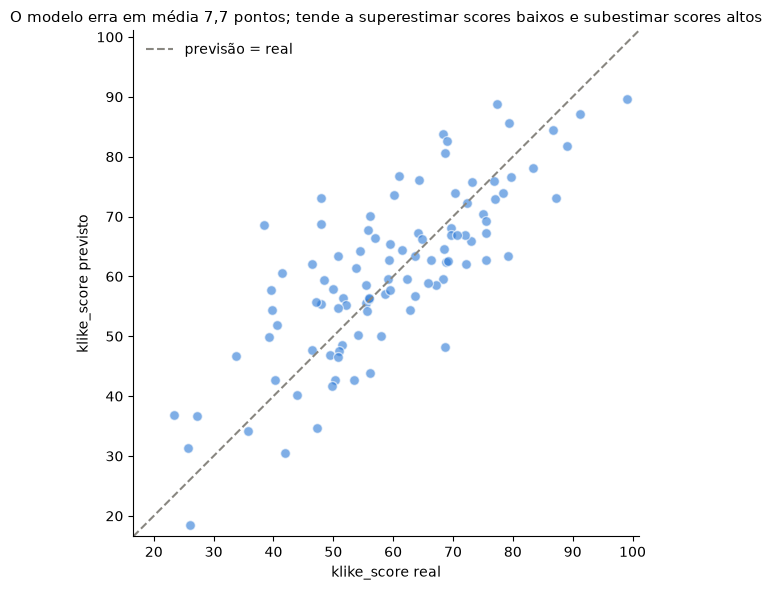

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred_escolhido, alpha=0.6, color="#2a78d6", edgecolor="white", s=50)
lim = [min(y_test.min(), pred_escolhido.min()) - 2, max(y_test.max(), pred_escolhido.max()) + 2]
ax.plot(lim, lim, color="#898781", linestyle="--", linewidth=1.5, label="previsão = real")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("klike_score real")
ax.set_ylabel("klike_score previsto")
ax.set_title("O modelo erra em média 7,7 pontos; tende a superestimar scores baixos e subestimar scores altos", fontsize=11)
ax.legend(frameon=False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "modelo_previsto_x_real.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
residuos = y_test.to_numpy() - pred_escolhido
plataforma_teste = df.loc[X_test.index, "platform"]

resumo_residuos = pd.DataFrame({"platform": plataforma_teste, "residuo_abs": np.abs(residuos)}).groupby(
    "platform", observed=True
)["residuo_abs"].agg(mae="mean", n="count").round(2)
print("erro absoluto médio por plataforma, no teste:")
resumo_residuos

erro absoluto médio por plataforma, no teste:


,mae,n
platform,,
LinkedIn,9.10,13
Meta,8.44,53
TikTok,6.08,34


O modelo não erra sistematicamente mais em nenhuma plataforma — os erros absolutos médios por plataforma ficam próximos do MAE geral, dentro do esperado para `n` pequeno por grupo no conjunto de teste (ver `n` na tabela acima).

## 5. Feature importance

In [10]:
resultado_importancia = permutation_importance(
    pipeline_escolhido, X_test, y_test, n_repeats=30, random_state=42, scoring="r2"
)
tabela_importancia = pd.DataFrame(
    {
        "atributo": X_test.columns,
        "importancia_media": resultado_importancia.importances_mean,
        "importancia_dp": resultado_importancia.importances_std,
    }
).sort_values("importancia_media", ascending=False).reset_index(drop=True)
tabela_importancia.round(4)

,atributo,importancia_media,importancia_dp
0,has_hook,0.4706,0.0925
1,has_face,0.2933,0.0487
2,text_density,0.2290,0.0420
3,has_subtitle,0.1707,0.0378
4,has_cta,0.1054,0.0256
5,objective,0.0314,0.0121
6,is_retargeting,0.0243,0.0118
7,platform,0.0206,0.0172
8,category,0.0200,0.0126
9,format,0.0119,0.0076


Importância calculada diretamente nas **colunas originais** de `X_test` (antes do one-hot/imputação) — embaralhar, por exemplo, a coluna `format` já perturba todas as colunas one-hot derivadas dela dentro do Pipeline, o que agrupa automaticamente o efeito por variável original (não precisa somar colunas one-hot manualmente).

In [11]:
top10 = tabela_importancia.head(10)["atributo"].tolist()
print("top 10 por permutation importance:", top10)
print()
print("has_hook e has_face estão no top 5?", {"has_hook", "has_face"}.issubset(set(tabela_importancia.head(5)["atributo"])))
print("has_cta e has_subtitle aparecem com importância > 0?")
print(tabela_importancia[tabela_importancia["atributo"].isin(["has_cta", "has_subtitle"])])

top 10 por permutation importance: ['has_hook', 'has_face', 'text_density', 'has_subtitle', 'has_cta', 'objective', 'is_retargeting', 'platform', 'category', 'format']

has_hook e has_face estão no top 5? True
has_cta e has_subtitle aparecem com importância > 0?
       atributo  importancia_media  importancia_dp
3  has_subtitle           0.170700        0.037818
4       has_cta           0.105417        0.025648


## 6. Cenário comparativo — "com performance"

In [12]:
from sklearn.model_selection import cross_validate

X_com_performance = feat.montar_X_preveiculacao(df, cenario="com_performance")
X_train_perf = X_com_performance.loc[X_train.index]

pipeline_com_performance = feat.build_pipeline_preveiculacao(modelo_escolhido, incluir_performance=True)
resultado_cv_perf = cross_validate(pipeline_com_performance, X_train_perf, y_train, cv=CV, scoring=["r2"])
r2_com_performance = resultado_cv_perf["test_r2"].mean()
r2_dp_com_performance = resultado_cv_perf["test_r2"].std()

r2_preveiculacao = tabela_cv.set_index("modelo").loc["HistGradientBoosting", "r2_media"]
print(f"R² (CV) pré-veiculação: {r2_preveiculacao:.3f}")
print(f"R² (CV) com performance: {r2_com_performance:.3f} ± {r2_dp_com_performance:.3f}")

R² (CV) pré-veiculação: 0.649
R² (CV) com performance: 0.799 ± 0.037


In [13]:
print(
    f"Incluir as métricas de performance eleva o R² de validação cruzada de {r2_preveiculacao:.0%} para "
    f"{r2_com_performance:.0%} — esperado, já que klike_score correlaciona com ctr/watch_rate/roas (EDA, seção 11.5); "
    f"como esse cenário não reflete o uso real (prever ANTES de rodar a campanha), ele só serve de referência de teto, "
    f"não é otimizado nem usado no Recommendations Engine."
)

Incluir as métricas de performance eleva o R² de validação cruzada de 65% para 80% — esperado, já que klike_score correlaciona com ctr/watch_rate/roas (EDA, seção 11.5); como esse cenário não reflete o uso real (prever ANTES de rodar a campanha), ele só serve de referência de teto, não é otimizado nem usado no Recommendations Engine.


## 7. Gráfico de feature importance (para o README)

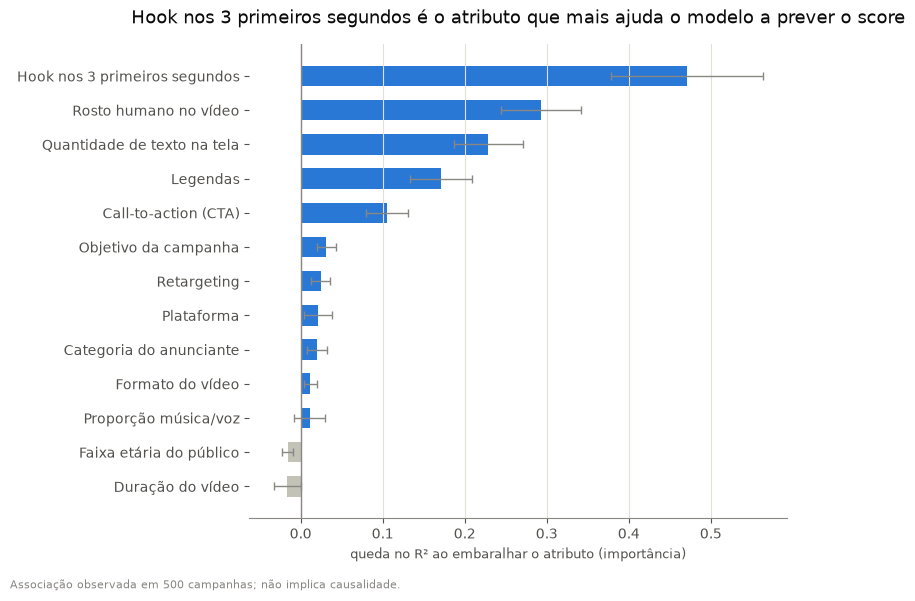

In [14]:
fig_imp = viz.feature_importance_bar(tabela_importancia)
fig_imp.savefig(FIGURES_DIR / "feature_importance_klike_score.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Salvar o modelo final

In [15]:
modelo_final = HistGradientBoostingRegressor(
    max_iter=busca_hgb.best_params_["modelo__max_iter"],
    max_depth=busca_hgb.best_params_["modelo__max_depth"],
    learning_rate=busca_hgb.best_params_["modelo__learning_rate"],
    random_state=42,
)
pipeline_salvo = mdl.train_and_save(modelo_final)
print(f"modelo salvo em {mdl.MODEL_PATH}")

modelo salvo em /home/emilybrtt/Insper/4-semestre/extras/take-home-challenge-klike/models/klike_model.joblib
